# Lab 3 · Introduction to Fixed Effects Models
## Does more RN time prevent pressure ulcers in nursing homes?

**Maths for Data Science III** · Guided lab: run every cell in order, from top to bottom.

**Dataset:** 800 US nursing homes observed every year from 2017 to 2024 (`nursing_home_panel.csv`). The data are simulated for teaching. They follow the structure of the nursing home data that the Centers for Medicare & Medicaid Services (CMS) publishes on Care Compare.

**Learning objectives.** By the end of this lab you will be able to:

1. Describe panel data and separate the variation *between* homes from the variation *within* each home over time.
2. Explain why comparing different homes can give a misleading answer when homes differ in ways we cannot measure.
3. Estimate a fixed effects model with `linearmodels.PanelOLS` and interpret its coefficient.
4. Add year effects and use standard errors clustered by home.

## The scenario

Pressure ulcers (pressure injuries) are a classic **nurse-sensitive outcome**: regular repositioning, skin checks and early treatment prevent most of them. For every nursing home, CMS reports two numbers that let us ask whether nurse staffing makes a difference:

- `pressure_ulcer_pct`: the percentage of high-risk long-stay residents who have a pressure ulcer;
- `rn_hprd`: registered nurse (RN) hours per resident per day.

To get a feel for the units: 0.1 hours per resident per day is 6 minutes per resident. In a home with 80 residents, that is one extra 8-hour RN shift every day.

**Research question:** *When a nursing home increases its RN time by one hour per resident per day, by how many percentage points does its pressure ulcer rate change?*

## Panel data and the fixed effects idea

A **panel** follows the same units over time. Here each home appears once a year, so every row is a **home-year**. We write $i$ for the home and $t$ for the year.

Homes differ in many ways that stay roughly the same from year to year: how sick their residents are, specialised units (wound care, ventilators, post-acute rehabilitation), the building, management and culture, the local labour market. Most of these are not in the data. A fixed effects model collects all of them into one term per home, $\alpha_i$:

$$\text{PressureUlcer}_{it} = \beta \, \text{RN}_{it} + \alpha_i + \varepsilon_{it}$$

| Term | Meaning |
|---|---|
| $\beta$ | The effect of RN time: what we want to estimate |
| $\alpha_i$ | The **fixed effect** of home $i$: everything about the home that does not change over time, measured or not |
| $\varepsilon_{it}$ | Everything else that varies from year to year |

If homes with sicker residents also employ more RNs, then $\alpha_i$ and RN time are related, and a comparison *across* homes mixes up the two. Fixed effects avoid this by comparing **each home with itself** in different years. Because $\alpha_i$ is the same in every year, it cancels out of that comparison.

## 1. Load the data

`linearmodels` is a Python package for panel data models. Install it once; you can skip this cell if it is already installed.

In [19]:
!pip install -q linearmodels


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS, compare

In [21]:
url = "https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/nursing_home_panel.csv"
df = pd.read_csv(url)
df.shape

(6191, 19)

Here is one home, `NH-0001`, over the eight years:

In [22]:
df.loc[df["facility_id"] == "NH-0001",
       ["facility_id", "year", "ownership_type", "nursing_cmi", "rn_hprd", "pressure_ulcer_pct"]]

,facility_id,year,ownership_type,nursing_cmi,rn_hprd,pressure_ulcer_pct
0,NH-0001,2017,For profit,1.33,0.745,4.35
1,NH-0001,2018,For profit,1.37,0.695,6.37
2,NH-0001,2019,For profit,1.32,0.804,4.97
3,NH-0001,2020,For profit,1.39,0.658,7.00
4,NH-0001,2021,For profit,1.39,0.662,8.56
5,NH-0001,2022,For profit,1.38,0.542,8.14
6,NH-0001,2023,For profit,1.39,0.733,8.04
7,NH-0001,2024,For profit,1.41,0.836,8.76


This is what a panel looks like: the same home in every year. Its ownership never changes, while its staffing and pressure ulcer rate move from year to year.

The columns used in this lab:

| Column | Meaning |
|---|---|
| `facility_id` | Home identifier (the unit $i$) |
| `year` | Calendar year (the period $t$) |
| `pressure_ulcer_pct` | % of high-risk long-stay residents with a pressure ulcer (our **outcome**) |
| `rn_hprd` | RN hours per resident per day (our main **explanatory variable**) |
| `nursing_cmi` | Nursing case-mix index: how much nursing care the residents need (higher means sicker residents) |
| `cna_hprd`, `contract_staff_pct` | Nurse aide hours per resident per day, and the % of nursing hours worked by agency staff (Section 7) |
| `ownership_type` | For profit, Non profit or Government (Section 9) |

## 2. Prepare the panel

Count how many years each home appears in the data:

In [23]:
df.groupby("facility_id").size().value_counts().sort_index()

2      4
3      5
4     24
5     11
6      9
7     13
8    734
Name: count, dtype: int64

Most homes (734) appear in all eight years. The others opened or closed during the period, so they have fewer rows. A panel in which not every unit appears in every period is called **unbalanced**. `PanelOLS` handles this without any extra work.

CMS does not report a pressure ulcer rate for homes with too few residents, so we drop those rows. Then we tell pandas which column identifies the home and which identifies the year. `PanelOLS` expects a two-level index: **entity first, time second**.

In [24]:
df = df.dropna(subset=["pressure_ulcer_pct"])
panel = df.set_index(["facility_id", "year"])

print("Home-years:", len(panel))
print("Homes:     ", panel.index.get_level_values("facility_id").nunique())

Home-years: 6110
Homes:      794


## 3. Describe the data

Before fitting any model, look at the variables we will use. Summary statistics over all home-years:

In [25]:
cols = ["pressure_ulcer_pct", "rn_hprd", "cna_hprd", "contract_staff_pct", "nursing_cmi"]
df[cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pressure_ulcer_pct,6110.0,7.72,2.47,0.00,6.03,7.71,9.34,17.31
rn_hprd,6110.0,0.64,0.25,0.08,0.47,0.64,0.80,1.53
cna_hprd,6110.0,2.23,0.30,1.26,2.02,2.22,2.43,3.39
contract_staff_pct,6110.0,6.49,4.77,0.00,3.10,5.60,8.90,38.20
nursing_cmi,6110.0,1.30,0.12,0.89,1.22,1.30,1.39,1.71


**Interpretation.**

- **Pressure ulcers:** in the average home-year, 7.7% of high-risk long-stay residents have a pressure ulcer. Half of all home-years fall between 6.0% and 9.3%, and the highest rate is 17.3%.
- **RN time:** 0.64 hours per resident per day on average, about 38 minutes per resident. It varies widely, from under 0.1 to 1.5 hours.
- **Nurse aide time:** 2.23 hours per resident per day, more than three times the RN time. Aides deliver most of the hands-on care.
- **Agency staff:** they work 6.5% of nursing hours in the average home-year, but up to 38% in some.
- **Case-mix index:** 1.30 on average, from 0.89 to 1.71. Higher values mean residents who need more nursing care.

Now look at the distributions of the outcome and of RN time:

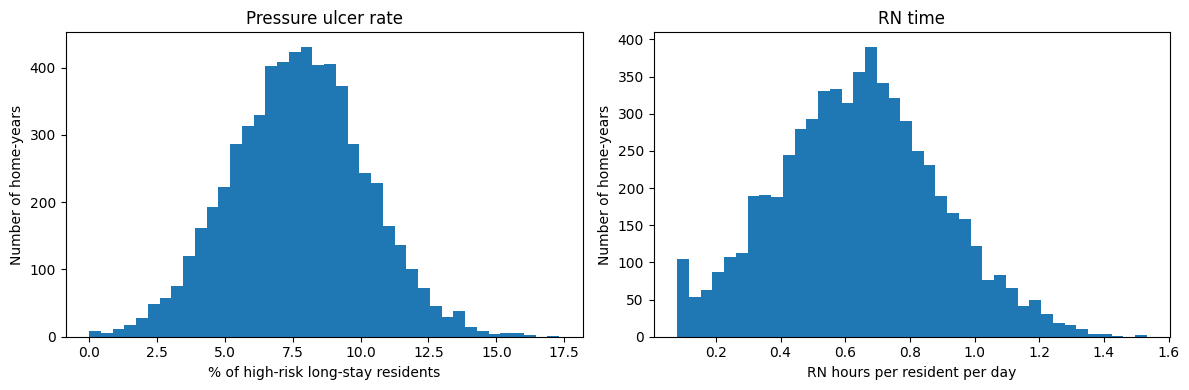

In [26]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

df["pressure_ulcer_pct"].plot.hist(ax=left, bins=40)
left.set_title("Pressure ulcer rate")
left.set_xlabel("% of high-risk long-stay residents")

df["rn_hprd"].plot.hist(ax=right, bins=40)
right.set_title("RN time")
right.set_xlabel("RN hours per resident per day")

for ax in (left, right):
    ax.set_ylabel("Number of home-years")

plt.tight_layout()
plt.show()

**How to read the plot**

- **Pressure ulcer rate:** a single peak, roughly symmetric around 7.7%, with no extreme values. Only a handful of home-years report no pressure ulcers at all.
- **RN time:** widely spread around its average of 0.64 hours. At the far left, 68 home-years (from 25 homes) report the lowest value in the data, 0.08 hours, or about 5 minutes per resident per day: these homes run with almost no RN time. At the other end, a few dozen home-years have more than twice the average.
- Neither variable shows values that look like data errors, so we keep every row.

### Between and within variation

RN time can vary in two ways:

- **Between homes:** some homes always staff more RNs than others.
- **Within a home:** the same home has more RN time in some years than in others.

To separate the two, compute each home's average over the years. The spread of these averages is the *between* variation. The spread of each year's value around its own home's average is the *within* variation.

In [27]:
home_avg = df.groupby("facility_id")["rn_hprd"].transform("mean")

print("Overall SD:     ", round(df["rn_hprd"].std(), 2))
print("Between-home SD:", round(df.groupby("facility_id")["rn_hprd"].mean().std(), 2))
print("Within-home SD: ", round((df["rn_hprd"] - home_avg).std(), 2))

Overall SD:      0.25
Between-home SD: 0.24
Within-home SD:  0.08


**Interpretation.** Homes differ a lot from each other (SD of 0.24 hours), but a given home changes its RN time much less from one year to the next (SD of 0.08 hours). A fixed effects model uses **only the within part**. That is its strength: it ignores the hard-to-compare differences between homes. It is also its cost: it works with less variation, so its estimates can be less precise.

## 4. Between homes versus within homes

Before fitting any model, look at the relationship between RN time and pressure ulcers in two different ways:

- **Left:** each dot is one home, plotted at its average RN time and average pressure ulcer rate over the years.
- **Right:** each dot is one home-year, measured from that home's own average. For example, +0.1 on the horizontal axis means "0.1 hours more RN time than this home usually has".

The small function `add_fit_line` draws the least-squares line through a cloud of points and returns its slope.

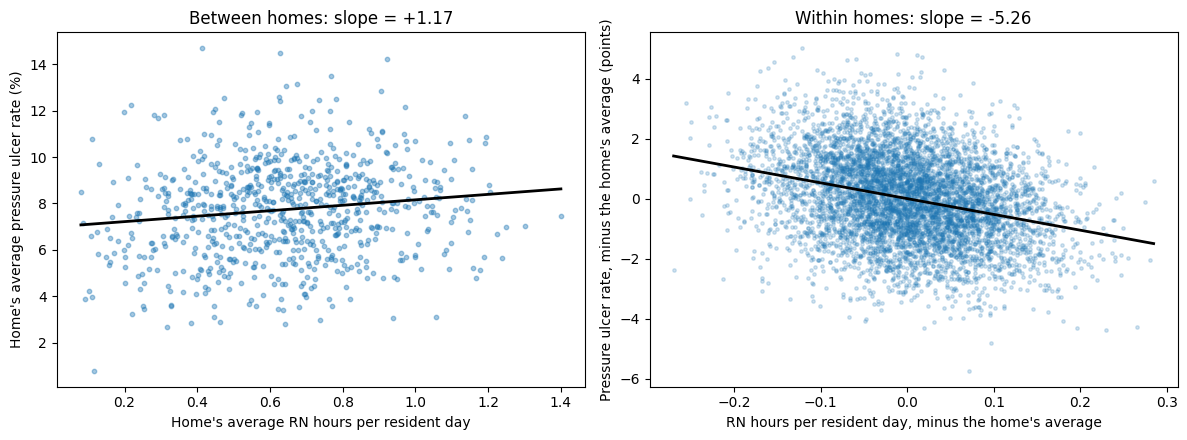

In [28]:
def add_fit_line(ax, x, y):
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, intercept + slope * xs, color="black", linewidth=2)
    return slope

# Left panel: one row per home, with its averages over the years
home_means = df.groupby("facility_id")[["rn_hprd", "pressure_ulcer_pct"]].mean()

# Right panel: each home-year minus its own home's average
deviations = df[["facility_id", "year"]].copy()
for col in ["rn_hprd", "pressure_ulcer_pct"]:
    deviations[col] = df[col] - df.groupby("facility_id")[col].transform("mean")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))

left.scatter(home_means["rn_hprd"], home_means["pressure_ulcer_pct"], s=10, alpha=0.4)
slope = add_fit_line(left, home_means["rn_hprd"], home_means["pressure_ulcer_pct"])
left.set_title(f"Between homes: slope = {slope:+.2f}")
left.set_xlabel("Home's average RN hours per resident day")
left.set_ylabel("Home's average pressure ulcer rate (%)")

right.scatter(deviations["rn_hprd"], deviations["pressure_ulcer_pct"], s=6, alpha=0.2)
slope = add_fit_line(right, deviations["rn_hprd"], deviations["pressure_ulcer_pct"])
right.set_title(f"Within homes: slope = {slope:+.2f}")
right.set_xlabel("RN hours per resident day, minus the home's average")
right.set_ylabel("Pressure ulcer rate, minus the home's average (points)")

plt.tight_layout()
plt.show()

**How to read the plot**

- **Left:** homes with more RN time have *somewhat higher* pressure ulcer rates on average (slope +1.17). Taken at face value, more RN time would mean more pressure ulcers.
- **Right:** when a home has more RN time than it usually does, its pressure ulcer rate is *lower* than usual (slope −5.26).
- The two views point in opposite directions. When a comparison between groups and a comparison within groups disagree like this, it is called **Simpson's paradox**.

**Before reading on:** think of a reason why homes with more RNs could have more pressure ulcers.

### Why do the two views disagree?

Homes whose residents are sicker (less mobile, more malnourished, more post-acute) need more RNs *and* have more pressure ulcers. The left panel mixes the effect of RN time with these differences in acuity, and with everything else that makes one home different from another: specialised units, culture, the building, the local staffing market. Most of these are not in the data, so we cannot simply control for them.

The right panel compares each home only with itself, so anything constant about the home drops out. This is exactly what a fixed effects model does: it estimates the right-hand slope.

## 5. The fixed effects model

In `PanelOLS`, the model from the introduction is written as a formula. Two notes on the code:

- `EntityEffects` gives every home its own intercept $\alpha_i$. No separate overall intercept is needed, because the home intercepts take its place.
- `cov_type="clustered", cluster_entity=True` requests standard errors **clustered by home**. The same home appears up to eight times, and its years resemble each other. Treating them as eight independent observations would make the standard errors too small. Clustering by home corrects this, and we use it for every model in this lab.

In [29]:
fe = PanelOLS.from_formula(
    "pressure_ulcer_pct ~ rn_hprd + EntityEffects", data=panel
).fit(cov_type="clustered", cluster_entity=True)
print(fe)

                          PanelOLS Estimation Summary                           
Dep. Variable:     pressure_ulcer_pct   R-squared:                        0.0887
Estimator:                   PanelOLS   R-squared (Between):             -1.0280
No. Observations:                6110   R-squared (Within):               0.0887
Date:                Thu, Oct 29 2026   R-squared (Overall):             -0.9978
Time:                        07:58:14   Log-likelihood                -1.054e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      517.46
Entities:                         794   P-value                           0.0000
Avg Obs:                       7.6952   Distribution:                  F(1,5315)
Min Obs:                       1.0000                                           
Max Obs:                       8.0000   F-statistic (robust):             532.38
                            

**Interpretation.**

- **`rn_hprd` = −5.26:** in years when a home has one more RN hour per resident per day than usual, its pressure ulcer rate is 5.3 points lower. The standard error is 0.23 and the 95% confidence interval runs from −5.71 to −4.81. This is the right-hand slope from Section 4.
- **F-test for Poolability** (bottom of the output): tests whether all homes could share a single intercept, that is, whether the home effects could be left out. F = 15.4 with p < 0.001, so the homes clearly differ and the fixed effects are needed.
- **R-squared (Within) = 0.089:** RN time explains about 9% of the year-to-year movement in each home's pressure ulcer rate. For a fixed effects model this is the R-squared to read. The *Between* and *Overall* versions measure something the model was not built to do, and they can even be negative.

### What `EntityEffects` does: subtracting each home's average

Giving every home its own intercept produces exactly the same slope as subtracting each home's average from every variable and then running an ordinary regression. We already built those deviations for the right-hand plot in Section 4:

In [30]:
within = PanelOLS.from_formula(
    "pressure_ulcer_pct ~ rn_hprd", data=deviations.set_index(["facility_id", "year"])
).fit()

print("Slope on deviations from home averages:", round(within.params["rn_hprd"], 3))
print("Slope with EntityEffects:              ", round(fe.params["rn_hprd"], 3))

Slope on deviations from home averages: -5.26
Slope with EntityEffects:               -5.26


The two slopes are identical. This is why the fixed effects estimator is also called the **within estimator**. (The standard errors of the manual version are slightly off, because it does not know that 794 home averages were estimated first. Let `PanelOLS` do it.)

## 6. Adding year effects

Fixed effects remove everything that stays constant **within a home**. But some things change for **all homes at the same time**. Between 2017 and 2024, the biggest of these was COVID-19. Plot the average across homes in each year:

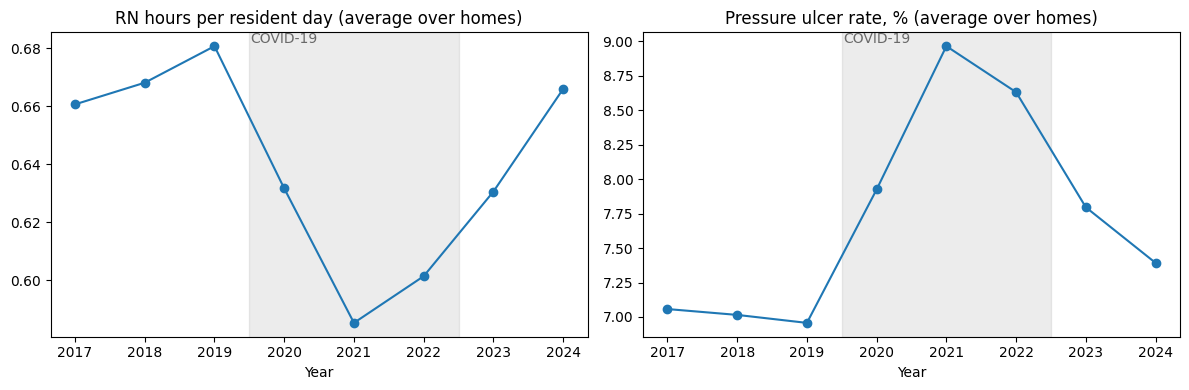

In [31]:
yearly = df.groupby("year")[["rn_hprd", "pressure_ulcer_pct"]].mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
yearly["rn_hprd"].plot(ax=left, marker="o")
left.set_title("RN hours per resident day (average over homes)")
yearly["pressure_ulcer_pct"].plot(ax=right, marker="o")
right.set_title("Pressure ulcer rate, % (average over homes)")

for ax in (left, right):
    ax.axvspan(2019.5, 2022.5, color="grey", alpha=0.15)
    ax.text(2020, ax.get_ylim()[1], "COVID-19", ha="center", va="top", color="dimgrey")
    ax.set_xlabel("Year")

plt.tight_layout()
plt.show()

**How to read the plot**

- Average RN time fell from 0.68 hours in 2019 to 0.59 in 2021. Over the same years the average pressure ulcer rate rose from 7.0% to 9.0%. Both had largely recovered by 2024.
- Both moved because of the pandemic: staff illness and shortages, infection-control workloads, sicker residents.
- The fixed effects model in Section 5 sees each home with less RN time *and* more pressure ulcers in 2021, and credits all of it to RN time. Part of it was the pandemic itself.

The fix is to add `TimeEffects`: one intercept per year, shared by all homes. It removes anything that affected every home in the same year. A model with both home and year effects is called a **two-way fixed effects** model:

$$\text{PressureUlcer}_{it} = \beta \, \text{RN}_{it} + \alpha_i + \gamma_t + \varepsilon_{it}$$

Here $\gamma_t$ is the **year effect**.

In [32]:
twfe = PanelOLS.from_formula(
    "pressure_ulcer_pct ~ rn_hprd + EntityEffects + TimeEffects", data=panel
).fit(cov_type="clustered", cluster_entity=True)
print(twfe)

                          PanelOLS Estimation Summary                           
Dep. Variable:     pressure_ulcer_pct   R-squared:                        0.0192
Estimator:                   PanelOLS   R-squared (Between):             -0.3991
No. Observations:                6110   R-squared (Within):               0.0606
Date:                Thu, Oct 29 2026   R-squared (Overall):             -0.3865
Time:                        07:58:15   Log-likelihood                   -9892.4
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      103.79
Entities:                         794   P-value                           0.0000
Avg Obs:                       7.6952   Distribution:                  F(1,5308)
Min Obs:                       1.0000                                           
Max Obs:                       8.0000   F-statistic (robust):             89.903
                            

**Interpretation.**

- **`rn_hprd` = −2.30:** comparing each home with itself, and after removing what happened to all homes in the same year, one more RN hour per resident per day lowers the pressure ulcer rate by 2.3 points. The standard error is 0.24 and the 95% confidence interval runs from −2.77 to −1.82.
- More than half of the −5.26 from Section 5 was the pandemic, not RN time.
- **In practical terms:** one extra 8-hour RN shift a day in an 80-resident home (+0.1 hours per resident per day) means about 0.23 points fewer high-risk residents with a pressure ulcer. With an average rate of about 7.7%, that is a relative reduction of roughly 3%.

**What fixed effects do not fix.** Home effects remove everything constant within a home, and year effects remove everything shared by all homes in a year. Something that changes *inside one home* at the same time as its RN time (a new director of nursing, an outbreak in that home only) could still bias the estimate.

## 7. The full staffing mix

RNs are not the only staff who matter. Nurse aides do most of the repositioning, and agency staff know the residents less well. Add both to the two-way fixed effects model:

In [33]:
full = PanelOLS.from_formula(
    "pressure_ulcer_pct ~ rn_hprd + cna_hprd + contract_staff_pct + EntityEffects + TimeEffects",
    data=panel,
).fit(cov_type="clustered", cluster_entity=True)
print(full)

                          PanelOLS Estimation Summary                           
Dep. Variable:     pressure_ulcer_pct   R-squared:                        0.0276
Estimator:                   PanelOLS   R-squared (Between):             -0.6391
No. Observations:                6110   R-squared (Within):               0.1552
Date:                Thu, Oct 29 2026   R-squared (Overall):             -0.6171
Time:                        07:58:15   Log-likelihood                   -9866.1
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      50.191
Entities:                         794   P-value                           0.0000
Avg Obs:                       7.6952   Distribution:                  F(3,5306)
Min Obs:                       1.0000                                           
Max Obs:                       8.0000   F-statistic (robust):             44.204
                            

**Interpretation.** Each coefficient holds the other staffing variables constant, and, as before, compares each home with itself after removing year-wide shocks.

- **`rn_hprd` = −2.26:** almost unchanged from −2.30, so the RN effect is not standing in for aide time or agency use.
- **`cna_hprd` = −0.51:** one more nurse aide hour per resident per day lowers the rate by about half a point (SE 0.17). Per hour, aide time matters less than RN time.
- **`contract_staff_pct` = 0.045:** when 10 percentage points more of a home's nursing hours are worked by agency staff, its pressure ulcer rate rises by about 0.45 points (SE 0.008). Continuity of care matters.

## 8. Comparing the models

`compare` puts the three fixed effects models side by side, with standard errors in parentheses:

In [34]:
models = {
    "Home FE": fe,
    "Home + year FE": twfe,
    "Full staffing mix": full,
}
print(compare(models, precision="std_errors", stars=True))

                                      Model Comparison                                      
                                       Home FE         Home + year FE      Full staffing mix
--------------------------------------------------------------------------------------------
Dep. Variable               pressure_ulcer_pct     pressure_ulcer_pct     pressure_ulcer_pct
Estimator                             PanelOLS               PanelOLS               PanelOLS
No. Observations                          6110                   6110                   6110
Cov. Est.                            Clustered              Clustered              Clustered
R-squared                               0.0887                 0.0192                 0.0276
R-Squared (Within)                      0.0887                 0.0606                 0.1552
R-Squared (Between)                    -1.0280                -0.3991                -0.6391
R-Squared (Overall)                    -0.9978                -0.3865 

The RN estimates as a **forest plot**: each point is an estimate of the effect of RN time and each line is its 95% confidence interval.

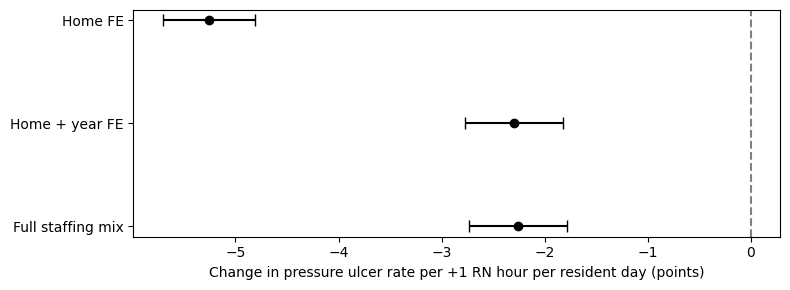

In [35]:
estimates = pd.DataFrame({
    "estimate": [m.params["rn_hprd"] for m in models.values()],
    "lower": [m.conf_int().loc["rn_hprd", "lower"] for m in models.values()],
    "upper": [m.conf_int().loc["rn_hprd", "upper"] for m in models.values()],
}, index=models.keys())

y = np.arange(len(estimates))[::-1]
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(estimates["estimate"], y,
            xerr=[estimates["estimate"] - estimates["lower"], estimates["upper"] - estimates["estimate"]],
            fmt="o", color="black", capsize=4)
ax.axvline(0, color="grey", linestyle="--")
ax.set_yticks(y, estimates.index)
ax.set_xlabel("Change in pressure ulcer rate per +1 RN hour per resident day (points)")
plt.tight_layout()
plt.show()

**How to read the plot.** Reading from top to bottom:

1. **Home FE** removes all constant differences between homes, but credits the pandemic to RN time.
2. **Home + year FE** also removes shocks shared by all homes, and the estimate falls by more than half.
3. **Full staffing mix** adds aide time and agency use, and the RN estimate barely moves.

The intervals of the first two models do not overlap: whether you include year effects changes the answer substantially.

## 10. Key takeaways

- **Panel data** follow the same units over time, so each unit can be compared with itself.
- Comparing **different homes** mixes the effect of RN time with everything else that differs between them. Across homes, more RN time even went with *more* pressure ulcers.
- **Fixed effects** (`EntityEffects`) give every home its own intercept. This removes all differences between homes that are constant over time, measured or not. The estimate uses only the variation **within** homes, and it equals the slope you get after subtracting each home's average.
- **Year effects** (`TimeEffects`) remove shocks that hit every home at once, such as COVID-19. Without them, the pandemic was credited to staffing.
- Use standard errors **clustered by home**, because the same home appears in several years.
- With home and year fixed effects, one more RN hour per resident per day lowers the pressure ulcer rate by about **2.3 percentage points** (95% CI 1.8 to 2.8).
- Fixed effects **cannot** estimate the effect of characteristics that never change within a home, such as ownership.

**Next:** random effects models, which can estimate time-invariant characteristics such as ownership, and the Hausman test for choosing between fixed and random effects.